# Phase 1: Evaluation protocol and baselines

We fix how translations between single-cell pseudobulk and whole-blood bulk RNA-seq profiles are scored, and which baselines they must beat, before any translation model is trained. Each translation is compared with its real partner profile on 135 validation pairs (14 donors), by evaluators fit on training targets only: accuracy (centered R²), realism (a classifier two-sample test, C2ST), composition recovery, and guards against collapse and copying. Unpaired alignment baselines refit on donor-disjoint halves of the training donors, the comparators for models trained without pairs, are no more accurate than predicting the training mean: the best centered R² is −0.093 in single-cell → bulk (mean shift) and −0.007 in bulk → single-cell (ComBat). The paired reference, ridge regression stretched by a factor chosen on the training donors (ridge + spread), reaches centered R² 0.126 (95% CI 0.066–0.182) and 0.224 (95% CI 0.167–0.296), and no baseline is both accurate and realistic. For models trained without pairs, the comparator is the unpaired accuracy–realism frontier traced by blending these baselines with each other and with the training-target mean (§3.8). The checkpoint-selection score has a donor-bootstrap SD of 0.035 and penalizes realistic sample-to-sample variation, so it selects checkpoints of the paired reference only, and claims are made per pre-specified hypothesis.

## 1. Aim

The translation models of later phases learn single-cell → bulk and bulk → single-cell maps without pairs, and are judged on two things: whether a translation reproduces the real partner of each held-out profile, and whether translations are indistinguishable from real profiles of the target domain. This phase defines the metrics for both, fixes the comparator that each rung of pairing (no pairs, composition supervision derived from pairs, full pairs) must beat, and measures how noisy these comparisons are with 14 validation donors. It also tests whether the metrics can be gamed by transformations that add no information, such as rescaling a regressor's outputs.

## 2. Data

We use the Sound Life cohort (Gong et al., 2025) as preprocessed in Phase 0: for each blood draw, a single-cell pseudobulk profile (PBMC scRNA-seq summed over cells) and a whole-blood bulk RNA-seq profile, both as log(1 + CP10k) on a 5,000-gene panel, with the measured fractions of six composition classes (T, monocyte, B, NK, dendritic cell, other) relative to PBMC.

- **Split** (Phase 0, donor-grouped): train 582 pairs (68 donors), validation 135 pairs (14 donors), test 119 pairs (14 donors). This phase uses train and validation only; the test donors are not used before Phase 6.
- **Training halves** (Phase 0): the 68 training donors are split into two donor-disjoint halves; half A supplies only single-cell profiles and half B only bulk profiles, so no pair is ever seen together. Halving 0 (primary): half A 33 donors and 288 draws, half B 35 donors and 294 draws. Halving 1 (sensitivity check): half A 35 donors and 291 draws, half B 33 donors and 291 draws; 19 of halving 0's 33 half-A donors are also in half A of halving 1.
- **What is fit on which data.** The evaluators are fit on the real target profiles, composition and age group of all 582 training pairs. Paired baselines are fit on all 582 training pairs. Unpaired baselines are fit twice: on all training profiles of both domains (pairing ignored), and on the training halves. Harmony additionally sees the validation source profiles at fit time, never the validation targets. Nothing is fit on validation targets: the validation pairs only score.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())   # repo root, wherever this runs from
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd

from dgm import paths
from dgm.data import load_pairs
from dgm.notebook import setup

info = setup(seed=0, notebook="phase1_evaluation.ipynb")                  # prints the commit these results come from
RESULTS = paths.results_dir(1)
FIG = paths.results_dir(1, "figures")

pairs = load_pairs()                  # schema-checked; built by phase0_preprocessing.ipynb
idx = {s: pairs.idx(s) for s in ("train", "val", "test")}
print({s: len(i) for s, i in idx.items()}, "| composition classes:", pairs.l1_classes.tolist())


commit: 23c6de4 | notebook_source: 94d4accbac08 (= HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: True


{'train': 582, 'val': 135, 'test': 119} | composition classes: ['T cell', 'Monocyte', 'B cell', 'NK cell', 'DC', 'Other']


In [2]:
import time
import matplotlib.pyplot as plt
from dgm.baselines import CORAL, ComBat, Harmony, Identity, MeanShift, PairedMLP, Ridge, RidgePCCalibration, RidgeSpread
from dgm.data import HALVING_SEEDS, train_halves
from dgm.metrics import DIST_PCS, Evaluator, c2st_null, donor_bootstrap
from dgm.plotting import DOMAIN, INK, INK_2, MUTED, SERIES, THRESHOLD, figure, label, panel_labels, save_show

tr, va = idx["train"], idx["val"]
classes = pairs.l1_classes.tolist()
genes = pairs.genes.tolist()
DIRECTIONS = {   # direction -> (source, target)
    "S->B": (pairs.x_sc, pairs.x_bulk),
    "B->S": (pairs.x_bulk, pairs.x_sc),
}
DIR_COLOR = {"S->B": DOMAIN["bulk"], "B->S": DOMAIN["single-cell"]}   # colored by target domain, as everywhere
# Display names for tables and figures: dgm.plotting.LABELS plus the names it lacks
DISPLAY = {"MLP (paired)": "paired MLP", "CORAL (abs 0.001)": "CORAL (absolute shrinkage 10⁻³)",
           "rank": "partner rank", "rank_median": "median partner rank", "within_chance": "within-donor chance",
           "mae": "MAE", "comp_mae": "composition MAE", "ci_low": "95% CI low", "ci_high": "95% CI high", "c2st": "C2ST AUROC",
           "null_mean": "null mean", "null_sd": "null SD", "composite_noise_sd": "selection-score SD (C2ST term)",
           "clusters": "clusters", "mixed_clusters": "mixed clusters", "centroid_gap_before": "centroid distance before",
           "centroid_gap_after": "centroid distance after", "max_coordinate_change": "largest coordinate change"}
def disp(n):
    return DISPLAY.get(n, label(n))

## 3. Methods

### 3.1 Problem and notation

For draw $i$, $x_{S,i} \in \mathbb{R}^G$ is the single-cell pseudobulk profile, $x_{B,i} \in \mathbb{R}^G$ the whole-blood bulk profile ($G = 5{,}000$ genes), and $c^*_i \in \Delta^{5}$ the measured composition over $K = 6$ classes. A translator $G_{S\to B}$ maps single-cell profiles to bulk-like profiles and $G_{B\to S}$ the reverse. For one direction we write $x$ for the source, $y$ for the real target and $\hat y = G(x)$ for the translation; outputs are clipped at 0. Each metric compares $\hat y_i$ with the real partner $y_i$ over the $n = 135$ validation draws. One evaluator is fit per direction on the training targets: the per-gene training mean $\mu$, a 50-component principal component analysis (PCA) of the training targets with scores $z(\cdot)$, a composition probe and an age classifier. These stay fixed for every translation scored afterwards.

### 3.2 Metrics

**Accuracy.**
- *Centered R²* (primary accuracy metric): $R^2_i = 1 - \lVert \hat y_i - y_i \rVert^2 / \lVert y_i - \mu \rVert^2$, reported as the median over draws. 0 means no better than predicting the training mean, 1 is perfect; unlike a correlation it falls when outputs are rescaled or noised.
- *Centered correlation*: $r_i = \operatorname{corr}(\hat y_i - \mu,\; y_i - \mu)$, the Pearson correlation across genes, median over draws.

**Pairing.** With similarities $s_{ij} = \cos(\hat y_i - \mu,\; y_j - \mu)$:
- *Partner rank*: $\text{rank}_i = \#\{ j : s_{ij} \ge s_{ii} \}$ over all validation targets (1 = best), reported as its median and as the *top-1 rate*, the fraction of draws with rank 1.
- *Within-donor partner rank*: the same rank restricted to the draws $j$ of the donor of $i$. The *within-donor top-1 rate* is the fraction of draws, among those whose donor has at least two draws, whose partner ranks first; its chance level is the mean over those draws of $1/n_{d(i)}$, with $n_{d(i)}$ the number of draws of that donor (0.104 on validation). It separates draw-level signal from donor identity.

**Realism.**
- *C2ST AUROC* (Lopez-Paz and Oquab, 2017) (primary realism metric): a classifier two-sample test that tells translations from real targets. Features are the scores on the top 10 target principal components (PCs) and their squares, so that a linear classifier sees a loss of spread as well as a shift. The classifier is an L2-regularized logistic regression (C = 1) on standardized features, evaluated by 5-fold cross-validation grouped by donor, so a donor's translated and real profiles always sit in the same fold; the AUROC is computed on the out-of-fold probabilities. 0.5 means indistinguishable. We report *realism* $= 1 - 2\,\lvert \text{AUROC} - 0.5 \rvert$ (1 = indistinguishable, 0 = perfectly separable).
- *C2ST null*: within each pair we swap at random which profile is labeled translated and which real (100 permutations). A value inside the null mean ± 2 SD cannot be told from chance. Values below 0.5 arise from noise; a value systematically below 0.5 arises only if translations copy *other* held-out real profiles, whose originals then sit in training folds with the opposite label. A model never sees held-out targets, so this cannot happen for a model, but it can for a probe built from real validation profiles (§4.9).
- *MMD²* (Gretton et al., 2012): the unbiased maximum mean discrepancy with an RBF kernel on the same top-10 PC scores, bandwidth set to the median pairwise distance among the real validation targets.

**Composition.**
- *Composition R² (ridge probe)*: a ridge regression $P$ from target profile to composition, fit on the training targets with its penalty chosen by donor-grouped 5-fold CV over $10^{-3}, \dots, 10^{4}$, is applied to the translations: $R^2_{\text{comp}} = \frac{1}{K}\sum_{k} \big[ 1 - \sum_i (P(\hat y_i)_k - c^*_{ik})^2 / \sum_i (c^*_{ik} - \bar c^*_k)^2 \big]$, with $\bar c^*_k$ the mean over the scored draws. *Composition correlation* is the mean over classes of the Pearson correlation of $P(\hat y)_k$ with $c^*_k$. The probe is independent of the composition networks a model may train against (Phase 2).
- *Marker ρ* (marker agreement): the mean over five lineages of the Spearman correlation between the translated expression of one marker gene and that lineage's fraction (CD2 for T cells, CD14 for monocytes, MS4A1 for B cells, KLRF1 for NK cells, FCER1A for dendritic cells).
- *Granulocyte gap* (single-cell → bulk only): the mean over the panel's granulocyte genes (from FCGR3B, CSF3R, CXCR2, CXCR1, FPR1, CMTM2, MME) of the translated minus the real mean expression. 0 means the translations match whole blood; PBMC-derived profiles lack these genes.

**Downstream (exploratory).** *Age AUROC*: a logistic regression (C = 0.1) on the 50 standardized target PC scores, trained to separate young from older training donors on their real targets, is applied to the translations; scores are averaged per donor and the AUROC is computed across donors.

**Non-collapse guards.**
- *Diversity ratio*: the mean pairwise Euclidean distance among translations divided by that among the real targets (1 = as diverse as real).
- *Nearest-neighbor ratio*: the median distance from a translation to its nearest training target divided by the same for the real targets ($\ll 1$ suggests copying training data).

The tables also report mean absolute error and the silhouette of translated vs. real profiles on their joint PCA. **References:** the probes applied to the real validation targets give what a perfect translation would score. They are references, not ceilings: a translation is built from its source, and the source can carry more of a signal than the real target does.

### 3.3 Uncertainty

Per-sample metrics get a donor bootstrap: the 14 validation donors are resampled with replacement (all draws of a resampled donor come along), the median is recomputed, and we report the 95% percentile interval over 1,000 resamples. The selection score depends on the C2ST, which is refit on each resample, so its bootstrap uses 200 resamples. The paired MLP is reported as the mean ± SD over 3 seeds.

### 3.4 Baselines

Every baseline translates the validation sources in both directions; outputs are clipped at 0. Unpaired baselines use only statistics of each domain separately, never which source goes with which target.

| Baseline | Information used | Description |
|---|---|---|
| identity | none | returns the source unchanged; the floor |
| mean shift | domain means | adds the per-gene difference of the training means of target and source |
| ComBat (Johnson et al., 2007) | domain means and variances | empirical-Bayes per-gene location and scale adjustment, with the target as the reference batch |
| CORAL (Sun et al., 2016) | domain means and covariances | $x \mapsto (x - \mu_S)\, C_S^{-1/2} C_T^{1/2} + \mu_T$, each covariance with a diagonal ridge of 1.0 × its mean variance (genes outnumber samples); a sensitivity row uses a fixed absolute ridge of $10^{-3}$ |
| Harmony (Korsunsky et al., 2019) | domain labels; validation sources at fit time | Harmony on a joint 50-PC PCA of the training source and target profiles, with the target batch's average correction undone and the result mapped back to genes |
| ridge | all training pairs | multi-output ridge regression from source to target, penalty by donor-grouped 5-fold CV over $10^{0}, \dots, 10^{6}$ |
| ridge + spread | all training pairs | ridge with its outputs stretched about the training-target mean by one factor $f \in \{1.0, 1.1, \dots, 2.5\}$, chosen to maximize the selection score on the training donors by cross-fitting (donor-grouped 5-fold; each fold's held-out predictions are scored by an evaluator fit on the other folds). It measures the most that rescaling alone, with no new information, can buy |
| ridge + PC calibration | all training pairs | ridge with the spread along each of the top 10 training-target PCs matched to the training targets' spread, using out-of-fold ridge predictions |
| paired MLP | all training pairs | the planned generator architecture (residual multilayer perceptron, 5,000 → 512 → 512 → 5,000, LayerNorm, LeakyReLU) trained as an L1 regressor, with early stopping on a donor-held-out 15% of the training donors; 3 seeds, hyperparameters not tuned |

### 3.5 Unpaired baselines on the training halves

Models trained without pairs see single-cell profiles from half A and bulk profiles from half B. We refit identity, mean shift, ComBat, CORAL and Harmony in exactly that setting: in single-cell → bulk the source statistics come from half A and the target statistics from half B, and in bulk → single-cell the reverse. Both halvings are fit; halving 0 is primary and halving 1 is a sensitivity check, not an independent replicate, since the two share 19 of 33 half-A donors. The evaluators are unchanged: they are part of the yardstick, not of any translator. These refits, not the fits on all training pairs, are the comparators for models trained without pairs.

### 3.6 The checkpoint-selection score

Per direction,

$$\text{selection score} = \tfrac13\Big[\, \max(R^2_{\text{centered}},0) \;+\; \big(1 - 2\,|\text{AUROC}_{\text{C2ST}} - 0.5|\big) \;+\; \max(R^2_{\text{comp}},0) \Big],$$

and the overall score is the mean over the two directions. It was fixed before any translation model was trained.

- **Accuracy**, $R^2_{\text{centered}}$, rewards getting *this sample* right beyond the shared average profile.
- **Realism**, the C2ST term, is 1 when translations cannot be told from real targets and 0 when they can be perfectly; outputs collapsed toward the mean read as unrealistic. This is what an adversarial model is meant to add over regression.
- **Composition**, $R^2_{\text{comp}}$ under the ridge probe, measures how well the measured cell-type fractions can be recovered from the translation. The probe is independent of the composition networks a model trains against, so a model cannot score here by fooling its own task network.

All three terms lie in [0, 1] with 1 ideal, so equal weights do not let one dominate by units, and a negative R² counts as 0, so one failed term cannot swamp the others. The accuracy and composition terms are R², not correlations, because correlations ignore scale: rescaling a regressor's outputs adds no information but raises a correlation-based score (§4.9). Rescaling does still buy realism, which is why ridge + spread is a baseline: it captures what rescaling alone can buy.

**What the score is used for.** It selects checkpoints and configurations on validation for the paired reference only. It cannot rank models trained without pairs: their centered R² is at or below 0, like every unpaired baseline's, so its accuracy term is constant. Those models are selected by the rule aligned with hypothesis H1 (§3.8): the checkpoint with the largest mean margin beyond the unpaired accuracy–realism frontier over the two directions. The score is never the criterion for a claim: it compares one translation with one real partner, so it rewards outputs near the conditional mean and penalizes realistic sample-to-sample variation (§4.9).

**Left out of the score on purpose (still reported):** mean absolute and squared error, which reward predicting the mean; the pairing ranks, which overlap with accuracy; age AUROC, since there is no age supervision and 14 validation donors make it noisy; diversity and the nearest-neighbor ratio, which are guards checked separately for collapse and copying.

### 3.7 How claims are made

- **Pre-specified hypotheses**, fixed before any translation model is trained and restated in Phase 3 Methods: H1, a model trained without pairs (CycleGAN [Zhu et al., 2017]) lies beyond the accuracy–realism frontier of the unpaired baselines (§3.8); H2, adding composition supervision derived from pairs improves composition under the marker probe; H3, the gap to the paired reference is reported without a claim.
- **Comparators match the information a model uses.** Models trained without pairs are compared with the unpaired baselines refit on the same training halves (§3.5), on each primary metric separately. The paired methods are an upper reference for what pairs can buy, not a bar for unpaired models.
- **Test.** Each claim is tested once, on the test donors in Phase 6, per direction: it holds only if the paired donor-bootstrap 95% CI of the difference between the model and its comparator (1,000 resamples of the test donors) excludes 0. Baselines keep their train-chosen settings and models their validation-chosen checkpoints.
- **Configuration count.** Every result reports how many configurations were compared on validation (at most 12 settings per model, each with 3 seeds).

### 3.8 The unpaired accuracy–realism frontier

Blending the outputs of two translators adds no information, so every blend $w\,\hat y_i + (1-w)\,\hat y_j$ (in log(1 + CP10k) space) of two members of the unpaired set is available to an unpaired method for free. The set holds mean shift, ComBat and CORAL, fit on the training halves, and the training-target mean of the target half (a constant output). Blends with the mean are the baselines shrunk toward it, which raises centered R² without adding information, so shrinkage alone cannot beat the frontier. Each pair's blends are scored on validation for accuracy (centered R²) and realism ($1 - 2\,|\text{AUROC}_{\text{C2ST}} - 0.5|$) at $w = 0, 0.1, \dots, 1$, and the path between neighboring weights is interpolated linearly, since blends are continuous in $w$ (a check against a 0.02 grid on halving 0 moved the frontier by at most 0.017). The frontier at accuracy $r$ is the best realism on any path with accuracy at least $r$:

$$F(r) = \max\{\,\text{realism}(p) : p \text{ on a blend path},\ R^2_{\text{centered}}(p) \ge r\,\}.$$

A model at accuracy $r$ and realism $s$ beats the frontier by the margin $s - F(r)$. If no point on any path is as accurate as the model, the margin is instead the model's accuracy lead over the most accurate point. Pairwise blends suffice: blends of three members and stretched blends stay within about 0.02 of the pairwise frontier. Identity and Harmony are dominated and not used (§4.9). The frontier is the H1 comparator (`dgm.frontier`). It contains every single baseline, so a model beyond it is better than any unpaired baseline at its accuracy, and it is stricter than any one baseline.

## 4. Results

All results in this section are on the validation set (135 pairs, 14 donors).

### 4.1 Reference scores of real profiles

**The probes recover composition, age and markers from real profiles of both domains, and composition far better from single-cell profiles than from whole blood.**

**Table 1.1.** Probes applied to the real validation targets: composition correlation and R² (ridge probe), composition mean absolute error, age AUROC (donor level) and marker ρ, per target domain (single-cell → bulk: real bulk; bulk → single-cell: real single-cell). The printed lines give the probe penalty chosen by cross-validation and the marker gene used for each lineage.

In [3]:
evaluators, references = {}, {}
for d, (src, tgt) in DIRECTIONS.items():
    ev = Evaluator(tgt[tr], pairs.composition[tr], pairs.age_group[tr], pairs.donor_ids[tr], genes, d)
    references[d] = ev.fit_reference(tgt[va], pairs.composition[va], pairs.age_group[va], pairs.donor_ids[va], classes)
    evaluators[d] = ev
    print(f"{d}: target = {'bulk' if d == 'S->B' else 'single-cell'}; composition probe alpha {ev.comp_alpha_:g}; "
          f"markers {ev.markers_}")
display(pd.DataFrame(references).T.rename(index=disp, columns=disp).style.format("{:.3f}")
        .set_caption("Probes applied to the real validation targets (135 pairs, 14 donors)"))

<env>/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=3.35225e-08): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


<env>/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=4.24099e-08): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


<env>/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=3.62341e-08): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


<env>/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=3.4148e-08): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


<env>/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:250: LinAlgWarning: Ill-conditioned matrix (rcond=3.5316e-08): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


S->B: target = bulk; composition probe alpha 10; markers {'T cell': 'CD2', 'B cell': 'MS4A1', 'Monocyte': 'CD14', 'NK cell': 'KLRF1', 'DC': 'FCER1A'}


B->S: target = single-cell; composition probe alpha 0.1; markers {'T cell': 'CD2', 'B cell': 'MS4A1', 'Monocyte': 'CD14', 'NK cell': 'KLRF1', 'DC': 'FCER1A'}


,composition correlation,composition R²,composition MAE,age AUROC,marker ρ
single-cell → bulk,0.694,0.481,0.015,0.959,0.491
bulk → single-cell,0.934,0.858,0.006,0.939,0.689


Real whole-blood bulk gives composition R² 0.481 (correlation 0.694), against 0.858 (0.934) for real single-cell profiles; age AUROC is 0.959 and 0.939, and marker ρ 0.491 and 0.689. The composition probe's penalty is chosen inside its grid in both domains (10 for bulk, 0.1 for single-cell). These are references, not ceilings: single-cell-derived outputs carry composition more directly than whole blood does (§4.2).

### 4.2 Baselines fit on all training pairs

**Fit on all training pairs, only the paired methods predict individual samples better than the training mean, and a per-gene mean shift removes most of the domain gap but no sample-specific structure.**

Each baseline is fit on the 582 training pairs and translates the 135 validation sources in both directions. The printed lines give each run's selection score, centered R², C2ST AUROC and composition R², its fit time, and the chosen ridge penalty, stretch factor or MLP stopping epoch.

In [4]:
MLP_SEEDS = (0, 1, 2)
results, per_sample, translations, harmony_diag, spread_fit = [], {}, {}, {}, {}
for d, (src, tgt) in DIRECTIONS.items():
    ev = evaluators[d]
    runs = [(m.name, m, None) for m in (Identity(), MeanShift(), ComBat(), CORAL(), CORAL(shrinkage=1e-3, relative=False), Harmony(),
                                         Ridge(), RidgeSpread(), RidgePCCalibration())]
    runs += [("MLP (paired)", PairedMLP(seed=s), s) for s in MLP_SEEDS]
    for name, model, seed in runs:
        t0 = time.time()
        if isinstance(model, Harmony):
            y_hat = model.fit_translate(src[tr], tgt[tr], src[va])
            harmony_diag[d] = model.diagnostics_
        elif isinstance(model, RidgeSpread):   # picks its stretch factor with the selection score, on train only
            y_hat = model.fit(src[tr], tgt[tr], pairs.donor_ids[tr], comp=pairs.composition[tr], age=pairs.age_group[tr],
                              genes=genes, direction=d).translate(src[va])
            spread_fit[d] = model                # kept for the accuracy-realism curve (figure 1.4)
        else:
            y_hat = model.fit(src[tr], tgt[tr], pairs.donor_ids[tr]).translate(src[va])
        fit_s = time.time() - t0
        m, ps = ev.score(y_hat, tgt[va], pairs.composition[va], pairs.age_group[va], pairs.donor_ids[va], classes)
        results.append({"direction": d, "baseline": name, "seed": seed, **m})   # fit time is printed, not saved, so the CSV is reproducible
        per_sample[(d, name, seed)] = ps
        translations[(d, name, seed)] = y_hat
        extra = (f"alpha {model.alpha_:g}, stretch factor {model.factor_:g}" if isinstance(model, RidgeSpread)
                 else f"alpha {model.alpha_:g}") if isinstance(model, Ridge) else (f"best epoch {model.best_epoch_}" if isinstance(model, PairedMLP) else "")
        print(f"{d} {name:18s} seed={seed}  composite {m['composite']:.3f}  r2 {m['r2_centered']:.3f}  "
              f"c2st {m['c2st_auroc']:.3f}  comp_r2 {m['comp_r2']:.3f}  ({fit_s:.0f}s) {extra}", flush=True)
res = pd.DataFrame(results)

S->B identity           seed=None  composite 0.000  r2 -14.026  c2st 1.000  comp_r2 -2.218  (0s) 


S->B mean shift         seed=None  composite 0.225  r2 0.000  c2st 0.903  comp_r2 0.482  (0s) 


S->B ComBat             seed=None  composite 0.375  r2 -0.327  c2st 0.740  comp_r2 0.605  (0s) 


S->B CORAL              seed=None  composite 0.384  r2 -0.216  c2st 0.438  comp_r2 0.276  (395s) 


S->B CORAL (abs 0.001)  seed=None  composite 0.257  r2 -0.860  c2st 0.614  comp_r2 -0.270  (191s) 


S->B Harmony            seed=None  composite 0.000  r2 -14.025  c2st 1.000  comp_r2 -2.257  (3s) 


... (38 outputs left out)

B->S ridge + PC calibration seed=None  composite 0.413  r2 0.120  c2st 0.573  comp_r2 0.266  (54s) alpha 100


B->S MLP (paired)       seed=0  composite 0.189  r2 -0.585  c2st 0.803  comp_r2 0.173  (2s) best epoch 101


B->S MLP (paired)       seed=1  composite 0.193  r2 -0.572  c2st 0.826  comp_r2 0.232  (3s) best epoch 120


B->S MLP (paired)       seed=2  composite 0.120  r2 -0.605  c2st 0.871  comp_r2 0.101  (2s) best epoch 98


**Table 1.2.** Harmony diagnostics, per direction: the number of Harmony clusters, the number holding at least 5% of each domain (mixed), the distance between the domain centroids on the joint PCA before and after correction, and the largest change of any coordinate.

In [5]:
display(pd.DataFrame(harmony_diag).T.rename(index=disp, columns=disp).style.format(
    {"clusters": "{:.0f}", "mixed clusters": "{:.0f}", "centroid distance before": "{:.1f}", "centroid distance after": "{:.1f}",
     "largest coordinate change": "{:.1e}"}))

,clusters,mixed clusters,centroid distance before,centroid distance after,largest coordinate change
single-cell → bulk,43,0,31.1,31.1,0.0e+00
bulk → single-cell,43,0,31.2,31.2,0.0e+00


**Table 1.3.** Every metric of §3.2 for each baseline fit on all training pairs, per direction (135 pairs, 14 donors), with the probes on the real targets as the last row; the paired MLP is the mean over 3 seeds, with its SD in the final table. CORAL (absolute shrinkage 10⁻³) is a sensitivity row, not a candidate. Saved as `baselines_val.csv` (every run) and `baselines_val_summary.csv` (this table).

In [6]:
KEY = ["composite", "r2_centered", "r_centered", "rank_median", "top1", "within_top1", "within_chance", "c2st_auroc", "mmd", "silhouette", "comp_r2", "comp_r",
       "marker_rho", "gran_gap", "age_auroc", "diversity", "nn_ratio", "mae"]
order = ["identity", "mean shift", "ComBat", "CORAL", "CORAL (abs 0.001)", "Harmony", "ridge (paired)", "ridge + spread", "ridge + PC calibration", "MLP (paired)"]
summary = res.groupby(["direction", "baseline"])[KEY].mean().reindex(pd.MultiIndex.from_product([list(DIRECTIONS), order]))
mlp_sd = res[res["baseline"] == "MLP (paired)"].groupby("direction")[KEY].std()
res.to_csv(RESULTS / "baselines_val.csv", index=False)
summary.to_csv(RESULTS / "baselines_val_summary.csv")
for d in DIRECTIONS:
    t = summary.loc[d].copy()
    for k, v in references[d].items():
        t.loc["real target (reference)", k] = v
    display(t.rename(index=disp, columns=disp).style.format("{:.3f}", na_rep="")
            .set_caption(f"{disp(d)}, validation (135 pairs, 14 donors)"))
display(mlp_sd.rename(index=disp, columns=disp).style.format("{:.3f}").set_caption("Paired MLP: SD over 3 seeds"))

,selection score,centered R²,centered correlation,median partner rank,top-1 partner rate,within-donor top-1 rate,within-donor chance,C2ST AUROC,MMD²,silhouette,composition R²,composition correlation,marker ρ,granulocyte gap,age AUROC,diversity ratio,nearest-neighbor ratio,MAE,composition MAE
identity,0.000,-14.026,0.048,56.000,0.007,0.096,0.104,1.000,1.437,0.776,-2.218,0.707,0.689,-2.041,0.551,0.628,3.187,0.258,
mean shift,0.225,0.000,0.290,5.000,0.230,0.289,0.104,0.903,0.079,0.079,0.482,0.708,0.689,-0.043,0.551,0.611,0.851,0.082,
ComBat,0.375,-0.327,0.321,5.000,0.237,0.289,0.104,0.740,0.029,0.026,0.605,0.795,0.689,-0.053,0.735,1.094,1.079,0.099,
CORAL,0.384,-0.216,0.318,18.000,0.141,0.185,0.104,0.438,0.019,0.016,0.276,0.574,0.466,0.031,0.571,0.902,0.904,0.094,
CORAL (absolute shrinkage 10⁻³),0.257,-0.860,0.236,32.000,0.089,0.148,0.104,0.614,0.039,0.033,-0.270,0.400,0.390,0.073,0.469,1.176,1.013,0.112,
Harmony,0.000,-14.025,0.035,60.000,0.007,0.096,0.104,1.000,1.436,0.779,-2.257,0.675,0.643,-2.031,0.551,0.543,3.166,0.258,
ridge,0.361,0.173,0.429,8.000,0.148,0.252,0.104,0.882,0.062,0.119,0.673,0.841,0.633,-0.042,0.898,0.408,0.724,0.075,
ridge + spread,0.497,0.126,0.429,8.000,0.148,0.252,0.104,0.622,0.026,0.036,0.609,0.841,0.633,-0.045,0.898,0.653,0.790,0.077,
ridge + PC calibration,0.419,-0.051,0.443,15.000,0.104,0.200,0.104,0.586,0.022,0.013,0.428,0.794,0.566,-0.056,0.878,0.860,0.809,0.084,
paired MLP,0.305,0.071,0.376,4.333,0.242,0.296,0.104,0.877,0.079,0.113,0.600,0.799,0.695,-0.062,0.673,0.567,0.837,0.079,


,selection score,centered R²,centered correlation,median partner rank,top-1 partner rate,within-donor top-1 rate,within-donor chance,C2ST AUROC,MMD²,silhouette,composition R²,composition correlation,marker ρ,granulocyte gap,age AUROC,diversity ratio,nearest-neighbor ratio,MAE,composition MAE
identity,0.000,-43.018,0.062,51.000,0.015,0.119,0.104,1.000,1.255,0.776,-296.921,0.531,0.491,,0.755,1.593,6.924,0.258,
mean shift,0.249,-1.470,0.297,5.000,0.178,0.222,0.104,0.627,0.016,0.065,-5.485,0.537,0.491,,0.776,1.473,1.794,0.076,
ComBat,0.082,-0.005,0.415,4.000,0.215,0.267,0.104,0.920,0.030,0.033,0.085,0.571,0.491,,0.898,0.759,1.025,0.040,
CORAL,0.271,-0.255,0.472,7.000,0.185,0.215,0.104,0.594,0.006,0.008,-0.052,0.636,0.504,,0.714,1.107,1.181,0.048,
CORAL (absolute shrinkage 10⁻³),0.011,-5.221,0.396,9.000,0.170,0.185,0.104,0.984,0.262,0.158,-6.224,0.532,0.366,,0.653,2.530,2.721,0.098,
Harmony,0.000,-42.279,0.042,53.000,0.015,0.119,0.104,1.000,1.253,0.783,-299.275,0.499,0.436,,0.755,1.221,6.811,0.254,
ridge,0.290,0.272,0.540,5.000,0.200,0.267,0.104,0.925,0.033,0.074,0.448,0.678,0.564,,0.816,0.470,0.749,0.032,
ridge + spread,0.393,0.224,0.539,5.000,0.200,0.267,0.104,0.701,0.010,0.012,0.357,0.678,0.564,,0.816,0.751,0.834,0.033,
ridge + PC calibration,0.413,0.120,0.516,7.000,0.163,0.259,0.104,0.573,0.014,0.009,0.266,0.646,0.532,,0.735,0.849,0.849,0.035,
paired MLP,0.167,-0.587,0.385,3.333,0.286,0.294,0.104,0.833,0.043,0.052,0.168,0.654,0.553,,0.973,1.098,1.403,0.059,


,selection score,centered R²,centered correlation,median partner rank,top-1 partner rate,within-donor top-1 rate,within-donor chance,C2ST AUROC,MMD²,silhouette,composition R²,composition correlation,marker ρ,granulocyte gap,age AUROC,diversity ratio,nearest-neighbor ratio,MAE
direction,,,,,,,,,,,,,,,,,,
bulk → single-cell,0.041,0.016,0.010,0.577,0.017,0.017,0.000,0.035,0.006,0.007,0.065,0.009,0.006,nan,0.024,0.003,0.003,0.000
single-cell → bulk,0.027,0.026,0.015,0.577,0.033,0.022,0.000,0.023,0.013,0.007,0.021,0.029,0.029,0.043,0.020,0.012,0.004,0.002


**Table 1.4.** Donor bootstrap of the per-sample accuracy metrics: the median over draws of centered R², centered correlation and partner rank, with its 95% CI (1,000 resamples of the 14 validation donors). The paired MLP is shown for seed 0.

In [7]:
rows = []
for (d, name, seed), ps in per_sample.items():
    if seed not in (None, 0):
        continue            # paired MLP: seed 0 shown; the seed SD is in Table 1.3
    for metric in ("r2_centered", "r_centered", "rank"):
        est, lo, hi = donor_bootstrap(ps[metric].to_numpy(), ps["donor"].to_numpy())
        rows.append({"direction": d, "baseline": name, "metric": metric, "median": est, "ci_low": lo, "ci_high": hi})
boot = pd.DataFrame(rows)
boot.to_csv(RESULTS / "baselines_val_bootstrap.csv", index=False)
display(boot.pivot_table(index=["direction", "baseline"], columns="metric", values=["median", "ci_low", "ci_high"])
        .reindex(pd.MultiIndex.from_product([list(DIRECTIONS), order])).rename(index=disp, columns=disp).style.format("{:.3f}"))

**Paired methods.** Ridge reaches centered R² 0.173 (95% CI 0.126–0.226) in single-cell → bulk and 0.272 (95% CI 0.239–0.350) in bulk → single-cell, and ridge + spread 0.126 (95% CI 0.066–0.182) and 0.224 (95% CI 0.167–0.296). Ridge + spread, stretched by a factor of 1.6 in both directions, has the highest overall selection score, 0.445 (single-cell → bulk 0.497, bulk → single-cell 0.393). Ridge + PC calibration scores 0.416 overall and is the best paired method in bulk → single-cell (0.413). Its target spread per component comes from the training targets' own PCA, which slightly overstates spread along those components, so it slightly overstretches.

**Most of the gap is a per-gene mean shift.** Mean shift raises the centered correlation from 0.048 (identity) to 0.290 in single-cell → bulk and from 0.062 to 0.297 in bulk → single-cell, and brings the granulocyte gap from −2.041 to −0.043. Its centered R² in single-cell → bulk is 0.000 (95% CI −0.055–0.047), the accuracy of predicting the training mean. What remains is sample-specific structure, which only the paired methods recover with clearly positive centered R².

**Harmony makes no correction on this data.** It finds 43 clusters, none of them mixed; the centroid distance is 31.1 before and after correction in single-cell → bulk (31.2 in bulk → single-cell), and no coordinate changes (Table 1.2). Its scores are close to identity's but not equal (single-cell → bulk composition correlation 0.675 vs. 0.707), because its output is a 50-PC reconstruction. On synthetic data where the domains overlap, the same implementation removes more than half the gap (`tests/test_baselines.py`), so this is a property of the data: the two modalities do not overlap.

**CORAL's covariance shrinkage matters.** With a fixed absolute ridge of $10^{-3}$, CORAL is much worse: selection score 0.257 and 0.011, diversity ratio 1.18 and 2.53, centered R² −0.86 and −5.2. With 582 samples and 5,000 genes, a tiny ridge on the covariance amplifies noise. CORAL applied to lower-dimensional embeddings may not be affected.

**The paired MLP ranks the true partner first most often** (top-1 rate 24% and 29%), but its centered R² is lower (0.071 and −0.587), and it collapses in single-cell → bulk (diversity ratio 0.567). With untuned hyperparameters, the generator architecture alone is not an advantage over ridge.

**Composition R² measures the composition signal a translation keeps, not bulk-likeness.** In single-cell → bulk, ridge (0.673), ridge + spread (0.609), ComBat (0.605) and the paired MLP (0.600) recover composition better than real bulk does (R² 0.481); mean shift (0.482) matches it, and CORAL (0.276), identity and Harmony fall below. Bulk-likeness is the C2ST's job.

### 4.3 The C2ST null

**Under the label-swap null the C2ST is centered at 0.49–0.50 with SD 0.037–0.042; among the baselines fit on all training pairs, only CORAL in single-cell → bulk and ridge + PC calibration in bulk → single-cell lie within 2 SD of it.**

**Table 1.5.** Observed C2ST AUROC and its null (100 within-pair label swaps) for each baseline fit on all training pairs: null mean, null SD, $z$ = (observed − null mean) / null SD, and the SD this puts into the selection score through the realism term alone (2 × null SD / 3).

In [8]:
rows = []
for d, (src, tgt) in DIRECTIONS.items():
    ev = evaluators[d]
    zy = ev.pca_.transform(tgt[va])[:, :DIST_PCS]
    for name in ["mean shift", "ComBat", "CORAL", "ridge (paired)", "ridge + spread", "ridge + PC calibration", "MLP (paired)"]:
        zh = ev.pca_.transform(translations[(d, name, 0 if name == "MLP (paired)" else None)])[:, :DIST_PCS]
        mu, sd = c2st_null(zh, zy, pairs.donor_ids[va], n_perm=100)
        obs = res[(res.direction == d) & (res.baseline == name) & ((res.seed == 0) if name == "MLP (paired)" else res.seed.isna())]["c2st_auroc"].iloc[0]
        rows.append({"direction": d, "baseline": name, "c2st": obs, "null_mean": mu, "null_sd": sd, "z": (obs - mu) / sd,
                     "composite_noise_sd": 2 * sd / 3})
null = pd.DataFrame(rows)
null.to_csv(RESULTS / "c2st_null_val.csv", index=False)
shown = null.assign(direction=null.direction.map(disp), baseline=null.baseline.map(disp)).rename(columns=disp)
display(shown.style.format({c: "{:.1f}" if c == "z" else "{:.3f}" for c in shown.columns[2:]}))
print(f"null SD across baselines: {null.null_sd.min():.3f}-{null.null_sd.max():.3f}; "
      f"selection-score noise from the C2ST term alone: ~{null.composite_noise_sd.mean():.3f} SD")

,direction,baseline,C2ST AUROC,null mean,null SD,z,selection-score SD (C2ST term)
0,single-cell → bulk,mean shift,0.903,0.502,0.040,9.9,0.027
1,single-cell → bulk,ComBat,0.740,0.499,0.040,5.9,0.027
2,single-cell → bulk,CORAL,0.438,0.504,0.037,-1.8,0.025
3,single-cell → bulk,ridge,0.882,0.500,0.039,9.7,0.026
4,single-cell → bulk,ridge + spread,0.622,0.498,0.039,3.2,0.026
5,single-cell → bulk,ridge + PC calibration,0.586,0.496,0.037,2.4,0.025
6,single-cell → bulk,paired MLP,0.853,0.501,0.038,9.1,0.026
7,bulk → single-cell,mean shift,0.627,0.500,0.042,3.0,0.028
8,bulk → single-cell,ComBat,0.920,0.496,0.039,11.0,0.026
9,bulk → single-cell,CORAL,0.594,0.498,0.042,2.3,0.028


null SD across baselines: 0.037-0.042; selection-score noise from the C2ST term alone: ~0.026 SD


CORAL fit on all training pairs has single-cell → bulk C2ST AUROC 0.438 ($z = -1.8$), indistinguishable from real profiles; fit on the training halves it is 0.605 (halving 0) and 0.750 (halving 1). Ridge + PC calibration in bulk → single-cell has $z = 1.9$. Every other baseline lies 2.3 to 11 null SDs above the null mean. The null SD puts about 0.026 (1 SD) of noise into the selection score through the realism term alone; the noise of the whole score is measured in §4.10.

### 4.4 Unpaired baselines refit on the training halves

**Refit on the training halves, no unpaired baseline is more accurate than the training mean, and each scores below its fit on all training pairs.**

**Tables 1.6–1.8.** Unpaired baselines fit on the training halves (§3.5) and scored on validation, for halving 0 (Table 1.6) and halving 1 (Table 1.7): selection score, centered R², C2ST AUROC, realism, composition R², top-1 and within-donor top-1 rates, diversity ratio and granulocyte gap. Table 1.8 gives the overall selection score (mean of the two directions) on each halving next to the same baseline fit on all training pairs. The printed lines give the size of each half. Saved as `baselines_val_halves.csv`.

In [9]:
UNPAIRED_RUNS = lambda: [Identity(), MeanShift(), ComBat(), CORAL(), Harmony()]
rows, half_translations, half_per_sample = [], {}, {}
for seed in HALVING_SEEDS:
    half_a, half_b = train_halves(pairs, seed)
    print(f"halving {seed}: half A {len(np.unique(pairs.donor_ids[half_a]))} donors, {len(half_a)} draws; "
          f"half B {len(np.unique(pairs.donor_ids[half_b]))} donors, {len(half_b)} draws")
    for d, (src, tgt) in DIRECTIONS.items():
        s_idx, t_idx = (half_a, half_b) if d == "S->B" else (half_b, half_a)   # single-cell from half A, bulk from half B
        for model in UNPAIRED_RUNS():
            if isinstance(model, Harmony):
                y_hat = model.fit_translate(src[s_idx], tgt[t_idx], src[va])
            else:
                y_hat = model.fit(src[s_idx], tgt[t_idx]).translate(src[va])
            m, ps = evaluators[d].score(y_hat, tgt[va], pairs.composition[va], pairs.age_group[va], pairs.donor_ids[va], classes)
            rows.append({"halving": seed, "direction": d, "baseline": model.name, **m})
            half_translations[(seed, d, model.name)] = y_hat
            half_per_sample[(seed, d, model.name)] = ps
halves_res = pd.DataFrame(rows)
shared_a = [set(pairs.donor_ids[train_halves(pairs, s)[0]]) for s in HALVING_SEEDS]
print(f"half-A donors of halving 0 also in half A of halving 1: {len(shared_a[0] & shared_a[1])} of {len(shared_a[0])}")
halves_res.to_csv(RESULTS / "baselines_val_halves.csv", index=False)
HKEY = ["composite", "r2_centered", "c2st_auroc", "comp_r2", "top1", "within_top1", "diversity", "gran_gap"]
for seed in HALVING_SEEDS:
    t = halves_res[halves_res.halving == seed].set_index(["direction", "baseline"])[HKEY].copy()
    t.insert(HKEY.index("c2st_auroc") + 1, "realism", 1 - 2 * (t["c2st_auroc"] - 0.5).abs())   # display only
    display(t.rename(index=disp, columns=disp).style.format("{:.3f}", na_rep="")
            .set_caption(f"Unpaired baselines fit on the training halves (halving {seed}), scored on validation"))
overall = halves_res.groupby(["halving", "baseline"])["composite"].mean().unstack(0)
overall["all training pairs"] = summary["composite"].unstack(0).mean(axis=1).reindex(overall.index)
display(overall.rename(index=disp, columns={0: "halving 0", 1: "halving 1"}).style.format("{:.3f}")
        .set_caption("Overall selection score (mean of the two directions): training halves vs. all training pairs"))

halving 0: half A 33 donors, 288 draws; half B 35 donors, 294 draws


halving 1: half A 35 donors, 291 draws; half B 33 donors, 291 draws


half-A donors of halving 0 also in half A of halving 1: 19 of 33


halving,halving 0,halving 1,all training pairs
baseline,,,
CORAL,0.180,0.177,0.327
ComBat,0.186,0.175,0.228
Harmony,0.000,0.000,0.000
identity,0.000,0.000,0.000
mean shift,0.199,0.199,0.237


**Best on each primary metric, halving 0** (single baselines; the frontier of their blends, which also includes the training mean, is in §4.9):
- single-cell → bulk: accuracy, mean shift (centered R² −0.093; halving 1: −0.024); realism, CORAL (0.790; halving 1: 0.501);
- bulk → single-cell: accuracy, ComBat (−0.007; halving 1: +0.015); realism, mean shift (0.575).

**Best selection score per direction:** ComBat in single-cell → bulk (0.311; halving 1: 0.313) and mean shift in bulk → single-cell (0.192; on halving 1, CORAL 0.187 and mean shift 0.175).

No unpaired baseline predicts a sample clearly better than the training mean: the best centered R² is ComBat's in bulk → single-cell, about 0 on both halvings (−0.007 and +0.015), and every other is negative. Refitting on the halves costs every non-trivial unpaired baseline selection score: overall, mean shift 0.199 on both halvings against 0.237 on all training pairs, ComBat 0.186 and 0.175 against 0.228, and CORAL 0.180 and 0.177 against 0.327. Halving 1 shares 19 of 33 half-A donors with halving 0, so its results are a sensitivity check, not an independent replicate.

### 4.5 Unpaired comparators against the paired reference

The figures below show the unpaired baselines fit on the training halves (halving 0) next to the paired methods fit on all training pairs. The difference in training data is part of the comparison and is encoded visibly (open vs. filled markers, grouped rows); both are scored on the same validation pairs by the same evaluators.

In [10]:
# What each figure compares: unpaired baselines fit on the training halves (halving 0; single-cell from half A, bulk from
# half B), the comparators for models trained without pairs, and paired methods fit on all training pairs, drawn as a
# reference for what pairs can buy. Both are scored on the same validation pairs by the same evaluators.
UNPAIRED_SHOWN = ["identity", "mean shift", "ComBat", "CORAL", "Harmony"]
PAIRED_SHOWN = ["ridge (paired)", "ridge + spread", "ridge + PC calibration", "MLP (paired)"]
FIG_ROWS = [(n, "unpaired") for n in UNPAIRED_SHOWN] + [(n, "paired") for n in PAIRED_SHOWN]
h0 = halves_res[halves_res.halving == 0].set_index(["direction", "baseline"])

def fig_metric(d, name, kind, k):
    return h0.loc[(d, name), k] if kind == "unpaired" else summary.loc[(d, name), k]

def fig_per_sample(d, name, kind):
    return half_per_sample[(0, d, name)] if kind == "unpaired" else per_sample[(d, name, 0 if name == "MLP (paired)" else None)]

def row_labels(ax):
    """Baseline names on the y-axis, grouped under 'unpaired (training halves)' and 'paired reference'.
    A blank row above the first baseline holds the first group heading, inside the axes and clear of the panel letter."""
    ax.set_yticks(ypos, [disp(n) for n, _ in FIG_ROWS])
    ax.set_ylim(ypos[0] - 1.6, ypos[-1] + 0.7)
    for y0, text in ((ypos[0] - 0.9, "unpaired, fit on training halves"), (ypos[len(UNPAIRED_SHOWN)] - 0.9, "paired reference, all training pairs")):
        ax.text(-0.02, y0, text, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=6.5, color=INK_2, style="italic")

ypos = np.r_[np.arange(len(UNPAIRED_SHOWN)), np.arange(len(PAIRED_SHOWN)) + len(UNPAIRED_SHOWN) + 1.0]

**The unpaired comparators and the paired reference differ mainly in accuracy: centered R² at or below 0 for every unpaired baseline, against 0.126 and 0.224 for ridge + spread.**

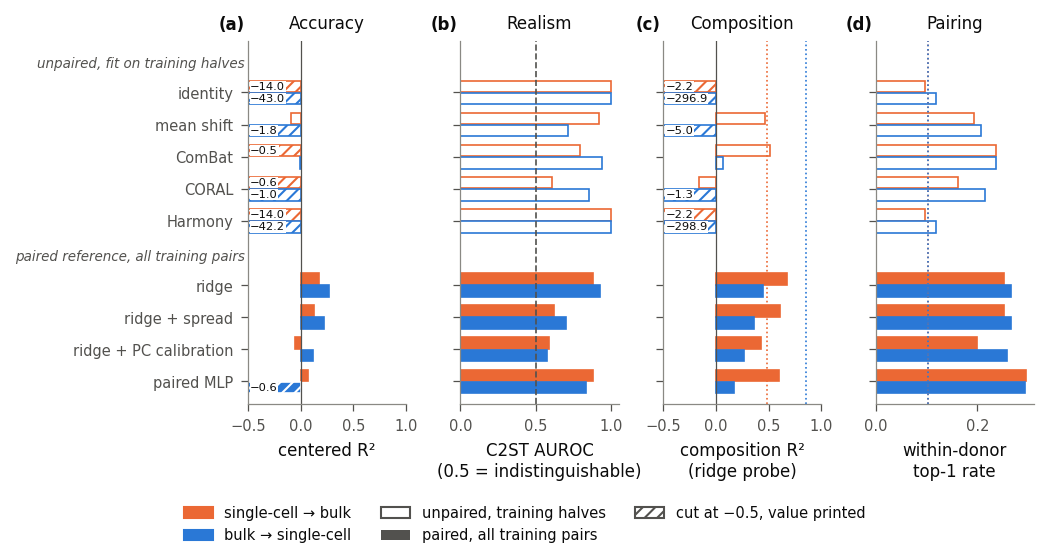

In [11]:
# Figure 1.1: accuracy, realism, composition and within-donor pairing of each baseline on validation, by direction.
CUT = -0.5
panels = [("r2_centered", "Accuracy", "centered R²"), ("c2st_auroc", "Realism", "C2ST AUROC\n(0.5 = indistinguishable)"),
          ("comp_r2", "Composition", "composition R²\n(ridge probe)"), ("within_top1", "Pairing", "within-donor\ntop-1 rate")]
fig, ax = figure("double", 3.6, 1, 4, sharey=True)
for a, (k, title, xlabel) in zip(ax, panels):
    for j, d in enumerate(DIRECTIONS):
        y = ypos + (j - 0.5) * 0.38
        vals = np.array([fig_metric(d, n, kind, k) for n, kind in FIG_ROWS], float)
        shown = np.maximum(vals, CUT) if k in ("r2_centered", "comp_r2") else vals
        for yy, v, raw, (n, kind) in zip(y, shown, vals, FIG_ROWS):
            cut = k in ("r2_centered", "comp_r2") and raw < CUT
            a.barh(yy, v, height=0.36, color=DIR_COLOR[d] if kind == "paired" else "white",
                   edgecolor="white" if (cut and kind == "paired") else DIR_COLOR[d], linewidth=0.8,
                   hatch="////" if cut else None)                 # hatched: the bar is cut at the axis edge
            if cut:                                                 # and its true value is printed
                a.text(CUT + 0.02, yy, f"{raw:.1f}".replace("-", "−"), va="center", fontsize=5.5, color=INK, bbox=dict(facecolor="white", edgecolor="none", pad=0.3))
        if k == "comp_r2":
            a.axvline(references[d]["comp_r2"], color=DIR_COLOR[d], ls=":", lw=0.8)
        if k == "within_top1":
            a.axvline(fig_metric(d, "ridge (paired)", "paired", "within_chance"), color=DIR_COLOR[d], ls=":", lw=0.8)
    if k == "c2st_auroc":
        a.axvline(0.5, **THRESHOLD)
    if k in ("r2_centered", "comp_r2"):
        a.axvline(0, color=INK_2, lw=0.6)
        a.set_xlim(CUT, 1.0)
    a.set(title=title, xlabel=xlabel)
row_labels(ax[0]); ax[0].invert_yaxis()
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor=DIR_COLOR[d], edgecolor=DIR_COLOR[d], label=label(d)) for d in DIRECTIONS] +
           [Patch(facecolor="white", edgecolor=INK_2, label="unpaired, training halves"),
            Patch(facecolor=INK_2, label="paired, all training pairs"),
            Patch(facecolor="white", edgecolor=INK_2, hatch="////", label="cut at −0.5, value printed")],
           loc="outside lower center", ncol=3)
panel_labels(ax)
save_show(fig, FIG, "1.1_baselines_val")

*Figure 1.1.* **Unpaired baselines fit on the training halves reach centered R² at or below 0, whereas paired methods fit on all training pairs reach up to 0.27.** Each bar is one baseline scored on the 135 validation pairs (14 donors) in single-cell → bulk (orange) and bulk → single-cell (blue). Open bars are unpaired baselines fit on the training halves (halving 0: single-cell profiles from 33 training donors, bulk profiles from 35 others), the comparators for models trained without pairs. Filled bars are paired methods fit on all 582 training pairs (68 donors), shown as a reference for what pairs can buy; the paired multilayer perceptron (MLP) is the mean of 3 seeds. Both groups are scored on the same validation pairs by the same evaluators. (a) Centered R², the median over samples of 1 − SSE/SST with SST taken around the target's per-gene training mean (0 = no better than predicting the training mean; higher is better). (b) Classifier two-sample test (C2ST) AUROC for telling translated from real target profiles; the dashed line marks 0.5, indistinguishable from real. (c) Composition R² of a ridge probe, trained on real training targets, applied to the translations (higher is better); dotted lines give the probe's score on the real validation targets (0.481 bulk, 0.858 single-cell). (d) Within-donor top-1 rate, the fraction of draws whose real partner is the most similar profile among the same donor's draws; the dotted line is chance (0.104). In (a) and (c), hatched bars are cut at −0.5 and their true value is printed on the bar. No unpaired baseline has positive centered R²; the paired methods do, except ridge + PC calibration (ridge with its spread calibrated along each principal component) in single-cell → bulk (−0.051) and the paired MLP in bulk → single-cell (−0.587).

The gap between the rungs, about 0.19 and 0.20 in selection score (ridge + spread 0.497 vs. ComBat 0.311 in single-cell → bulk; 0.393 vs. mean shift 0.192 in bulk → single-cell), and in centered R² from about 0 or below to 0.126 and 0.224, is what pairs buy, and the room a model trained without pairs has to fill.

### 4.6 Ranking a draw's partner among its donor's other draws

**Ranking a sample's partner among its donor's other draws does not need pairs.** The rate at which the true partner ranks first among the same donor's draws (chance 0.104; figure 1.1d) is similar for every method that corrects the domain shift: 0.20–0.30 for the paired methods; 0.16–0.24 for the unpaired baselines on halving 0, and up to 0.30 on halving 1 (mean shift). Fit on all training pairs, mean shift and ComBat (0.289 in single-cell → bulk) match or exceed ridge (0.252). With about 135 draws the rate's standard error is about 0.04, so these differences are within noise. The draw-level signal is carried by the source profile itself, and pairs do not add to it here.

### 4.7 Per-sample accuracy

**Every unpaired baseline has a median per-sample centered R² at or below 0; ridge and ridge + spread have medians above 0 in both directions.**

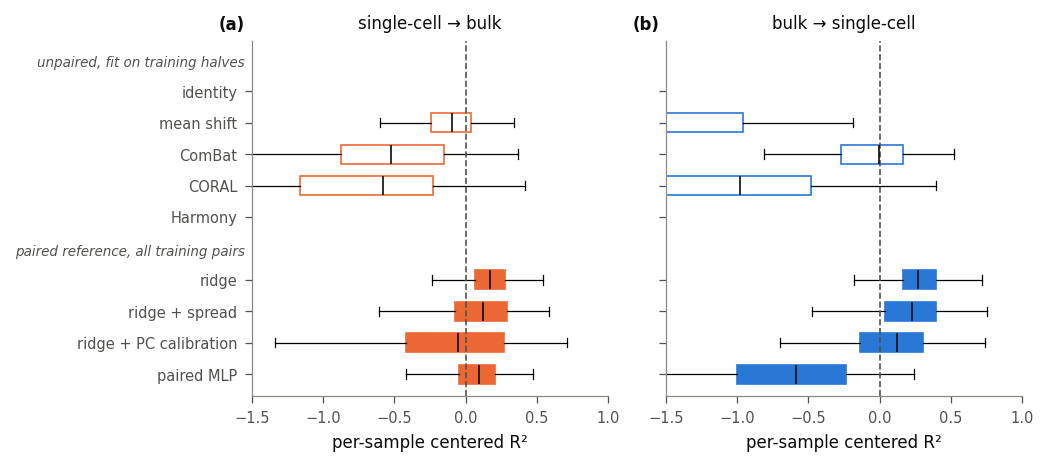

In [12]:
# Figure 1.2: per-sample centered R² with the real partner on validation.
fig, ax = figure("double", 3.0, 1, 2, sharey=True)
for a, d in zip(ax, DIRECTIONS):
    data = [fig_per_sample(d, n, kind)["r2_centered"].to_numpy() for n, kind in FIG_ROWS]
    bp = a.boxplot(data, positions=ypos, vert=False, widths=0.6, patch_artist=True, showfliers=False,
                   medianprops=dict(color=INK, lw=0.8), whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6))
    for b, (n, kind) in zip(bp["boxes"], FIG_ROWS):
        b.set(facecolor=DIR_COLOR[d] if kind == "paired" else "white", edgecolor=DIR_COLOR[d], linewidth=0.8)
    a.axvline(0, **THRESHOLD)
    a.set_xlim(-1.5, 1)
    a.set(xlabel="per-sample centered R²", title=label(d))
row_labels(ax[0]); ax[0].invert_yaxis()
panel_labels(ax)
save_show(fig, FIG, "1.2_per_sample_accuracy")

*Figure 1.2.* **Only the paired regressors place most validation samples above the accuracy of the training mean.** Distribution over the 135 validation pairs (14 donors) of each sample's centered R² with its real partner, 1 − ‖ŷ − y‖² / ‖y − μ‖², where μ is the target's per-gene training mean; the dashed line at 0 is the accuracy of predicting μ. (a) Single-cell → bulk; (b) bulk → single-cell. Open boxes are unpaired baselines fit on the training halves (halving 0), the comparators for models trained without pairs; filled boxes are paired methods fit on all training pairs, a reference (paired multilayer perceptron, MLP: seed 0). Boxes span the interquartile range with the median marked; whiskers reach the furthest sample within 1.5 times the interquartile range; outliers are not drawn. The axis is cut at −1.5. Identity and Harmony lie entirely below the axis (medians −14.026 and −14.022 in single-cell → bulk, −43.018 and −42.222 in bulk → single-cell), and mean shift in bulk → single-cell (median −1.750) lies partly below it. Every unpaired baseline has its median at or below 0, while ridge and ridge + spread have medians above 0 in both directions.

### 4.8 Translations on the target principal components

**Ridge collapses translations toward the center of the real profiles; stretching restores the spread, and CORAL overshoots it.**

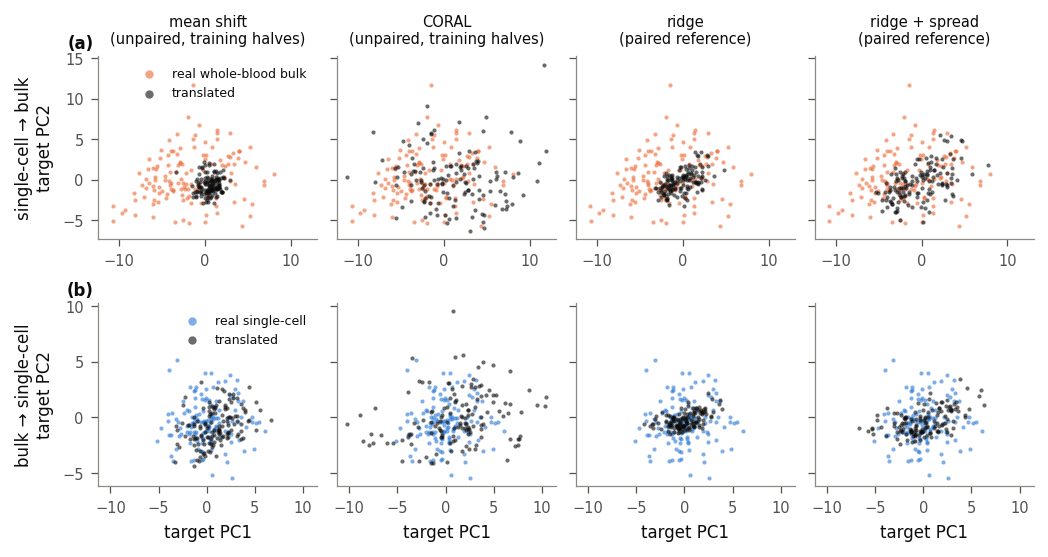

In [13]:
# Figure 1.3: translated vs real validation targets on the target PCA (fit on training targets).
show_b = [("mean shift", "unpaired"), ("CORAL", "unpaired"), ("ridge (paired)", "paired"), ("ridge + spread", "paired")]
fig, ax = figure("double", 3.6, 2, 4, sharex="row", sharey="row")
for r, d in enumerate(DIRECTIONS):
    ev, (src, tgt) = evaluators[d], DIRECTIONS[d]
    zr = ev.pca_.transform(tgt[va])
    tgt_name = "bulk" if d == "S->B" else "single-cell"
    for col, (name, kind) in enumerate(show_b):
        yh = half_translations[(0, d, name)] if kind == "unpaired" else translations[(d, name, None)]
        zh = ev.pca_.transform(yh)
        a = ax[r, col]
        a.scatter(*zr[:, :2].T, s=4, color=DOMAIN[tgt_name], alpha=0.6, linewidths=0, label=f"real {label(tgt_name)}", rasterized=True)
        a.scatter(*zh[:, :2].T, s=4, color=INK, alpha=0.6, linewidths=0, label="translated", rasterized=True)
        if r == 0:
            a.set_title(f"{disp(name)}\n({'unpaired, training halves' if kind == 'unpaired' else 'paired reference'})", fontsize=7)
        a.set(xlabel="target PC1" if r == 1 else "", ylabel=f"{label(d)}\ntarget PC2" if col == 0 else "")
    ax[r, 0].legend(markerscale=2, loc="best", fontsize=6)
panel_labels(ax[:, 0])   # (a) single-cell → bulk, (b) bulk → single-cell
save_show(fig, FIG, "1.3_translation_pca")

*Figure 1.3.* **Ridge regression collapses translations toward the center of the real profiles; stretching it, or recolouring the covariance with CORAL, restores spread.** Translated (black) and real (color) validation profiles, 135 pairs from 14 donors, on the first two principal components (PCs) of the target domain, fit on the real training targets. (a) Single-cell → bulk, with real whole-blood bulk in orange; (b) bulk → single-cell, with real single-cell pseudobulk in blue. Columns, left to right: mean shift and CORAL, unpaired baselines fit on the training halves (halving 0); ridge and ridge + spread, paired methods fit on all training pairs (a reference). In single-cell → bulk, mean shift and ridge concentrate their translations near the center of the real cloud (diversity, the mean pairwise distance between translations relative to that between real targets, 0.612 and 0.408), ridge + spread widens them (0.653) and CORAL overshoots (1.125). In bulk → single-cell, ridge collapses (0.470) while mean shift does not (1.470).

### 4.9 Accuracy against realism, and what rescaling can buy

**No baseline is both accurate and realistic.** Plain ridge has the best accuracy (centered R² 0.173 and 0.272) but collapses toward the mean (C2ST AUROC 0.882 and 0.925). The most realistic unpaired baseline in single-cell → bulk, CORAL on halving 0 (realism 0.790), has centered R² −0.578; mean shift and ComBat, the most accurate unpaired baselines, are far from realistic.

**Blends of the unpaired baselines and the training mean trace a frontier well above the single baselines.** On halving 0 the frontier reaches realism 0.667 at centered R² −0.2 in single-cell → bulk and 0.517 at −0.1 in bulk → single-cell, and shrinking toward the training mean makes unpaired outputs more accurate than the mean itself: the most accurate points on the blend paths reach centered R² 0.030 and 0.165 (Table 1.13). The frontier is higher on halving 1 (0.704 and 0.722 at the same accuracies), so it depends on which donors are in the halves. Identity and Harmony lie far inside it (Table 1.12).

In [14]:
# The unpaired accuracy-realism frontier (section 3.8): every blend of two of mean shift, ComBat, CORAL and the
# training-target mean (all from the training halves), scored on validation, for both halvings.
from dgm.frontier import MEAN, frontier_margin, frontier_realism, trace
FRONTIER_BASELINES = ["mean shift", "ComBat", "CORAL"]
fr = []
for seed in HALVING_SEEDS:
    for d, (src, tgt) in DIRECTIONS.items():
        def acc_real(y, d=d, tgt=tgt):
            m, _ = evaluators[d].score(y, tgt[va], pairs.composition[va], pairs.age_group[va], pairs.donor_ids[va], classes)
            return m["r2_centered"], 1 - 2 * abs(m["c2st_auroc"] - 0.5)
        half_a, half_b = train_halves(pairs, seed)
        members = {n: half_translations[(seed, d, n)] for n in FRONTIER_BASELINES}
        members[MEAN] = np.tile(tgt[half_b if d == "S->B" else half_a].mean(0), (len(va), 1))   # target half's mean
        t = trace(members, acc_real)
        t.insert(0, "direction", d); t.insert(0, "halving", seed)
        fr.append(t)
frontier = pd.concat(fr, ignore_index=True)
frontier.to_csv(RESULTS / "frontier_val_halves.csv", index=False)
rows = []
for seed in HALVING_SEEDS:
    for d in DIRECTIONS:
        pts = frontier[(frontier.halving == seed) & (frontier.direction == d)]
        for name in ["identity", "Harmony"]:                       # the baselines left out: dominated by the blends?
            r = halves_res[(halves_res.halving == seed) & (halves_res.direction == d) & (halves_res.baseline == name)].iloc[0]
            m, kind = frontier_margin(pts, r["r2_centered"], 1 - 2 * abs(r["c2st_auroc"] - 0.5))
            rows.append({"halving": seed, "direction": label(d), "baseline": name, "margin beyond the frontier": m, "margin kind": kind})
display(pd.DataFrame(rows).style.format({"margin beyond the frontier": "{:.3f}"}).hide(axis="index")
        .set_caption("Table 1.12. Identity and Harmony against the frontier of blends (negative = inside the frontier)"))
AT = [-0.6, -0.4, -0.3, -0.2, -0.1, -0.05, 0.0]
env_tab = pd.DataFrame([{"halving": seed, "direction": label(d), "most accurate point": frontier[(frontier.halving == seed) & (frontier.direction == d)]["r2_centered"].max(),
                         **{f"F({r})": frontier_realism(frontier[(frontier.halving == seed) & (frontier.direction == d)], r) for r in AT}}
                        for seed in HALVING_SEEDS for d in DIRECTIONS])
display(env_tab.style.format("{:.3f}", subset=env_tab.columns[2:]).hide(axis="index")
        .set_caption("Table 1.13. The unpaired frontier on validation: best realism F(r) reachable at accuracy at least r, and the most accurate point on any blend path"))


<env>/lib/python3.10/site-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


<env>/lib/python3.10/site-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


<env>/lib/python3.10/site-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


<env>/lib/python3.10/site-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


halving,direction,baseline,margin beyond the frontier,margin kind
0,single-cell → bulk,identity,-0.807,realism
0,single-cell → bulk,Harmony,-0.807,realism
0,bulk → single-cell,identity,-0.583,realism
0,bulk → single-cell,Harmony,-0.583,realism
1,single-cell → bulk,identity,-0.706,realism
1,single-cell → bulk,Harmony,-0.706,realism
1,bulk → single-cell,identity,-0.772,realism
1,bulk → single-cell,Harmony,-0.772,realism


halving,direction,most accurate point,F(-0.6),F(-0.4),F(-0.3),F(-0.2),F(-0.1),F(-0.05),F(0.0)
0,single-cell → bulk,0.030,0.807,0.796,0.763,0.667,0.517,0.377,0.223
0,bulk → single-cell,0.165,0.576,0.576,0.576,0.568,0.517,0.467,0.400
1,single-cell → bulk,0.084,0.706,0.706,0.706,0.704,0.653,0.575,0.395
1,bulk → single-cell,0.169,0.772,0.772,0.772,0.761,0.722,0.666,0.609


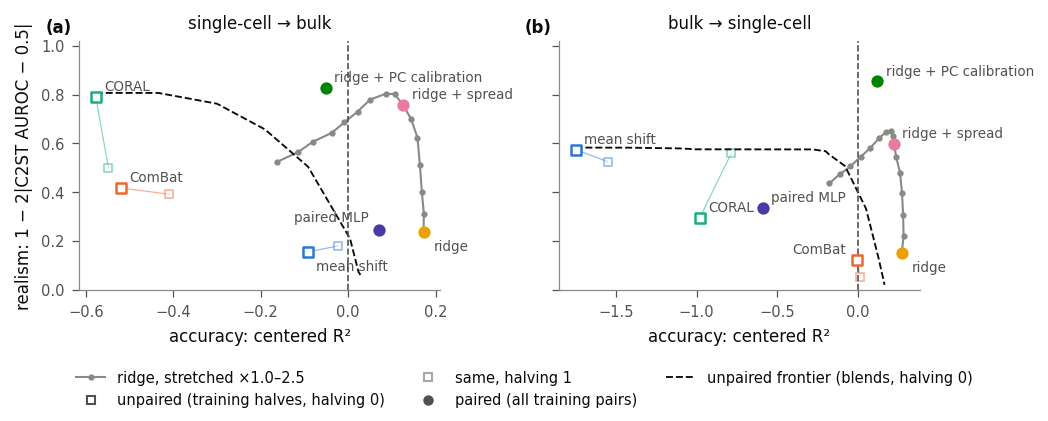

In [15]:
from dgm.frontier import envelope
# Figure 1.4: accuracy vs realism on validation. The line traces ridge stretched about the training-target mean by factors
# 1.0-2.5, i.e. what rescaling a regressor (no new information) can trade; points are the baselines.
FACTORS = np.round(np.arange(1.0, 2.51, 0.1), 2)
rows = []
for d, (src, tgt) in DIRECTIONS.items():
    for f in FACTORS:
        m, _ = evaluators[d].score(spread_fit[d].translate_at(src[va], f), tgt[va], pairs.composition[va], pairs.age_group[va],
                                   pairs.donor_ids[va], classes)
        rows.append({"direction": d, "factor": f, "r2_centered": m["r2_centered"], "c2st_auroc": m["c2st_auroc"], "composite": m["composite"]})
curve = pd.DataFrame(rows)
curve["realism"] = 1 - 2 * (curve["c2st_auroc"] - 0.5).abs()
curve.to_csv(RESULTS / "accuracy_realism_curve_val.csv", index=False)

points = [("mean shift", "unpaired"), ("ComBat", "unpaired"), ("CORAL", "unpaired"),
          ("ridge (paired)", "paired"), ("ridge + spread", "paired"), ("ridge + PC calibration", "paired"), ("MLP (paired)", "paired")]
h0 = halves_res[halves_res.halving == 0].set_index(["direction", "baseline"])
h1 = halves_res[halves_res.halving == 1].set_index(["direction", "baseline"])
# label offsets (points) and alignment where the default (up and to the right) would collide
LABEL_AT = {("S->B", "mean shift"): (4, -9, "left"), ("S->B", "MLP (paired)"): (-5, 4, "right"),
            ("S->B", "ridge (paired)"): (5, -9, "left"), ("B->S", "ComBat"): (-5, 3, "right"),
            ("B->S", "ridge (paired)"): (5, -9, "left")}
fig, ax = figure("double", 2.7, 1, 2, sharey=True)
for a, d in zip(ax, DIRECTIONS):
    cv = curve[curve.direction == d]
    a.plot(cv["r2_centered"], cv["realism"], color=MUTED, lw=1, marker="o", ms=2, zorder=1, label="ridge, stretched ×1.0–2.5")
    for k, (name, kind) in enumerate(points):
        row = h0.loc[(d, name)] if kind == "unpaired" else summary.loc[(d, name)]
        x, y = row["r2_centered"], 1 - 2 * abs(row["c2st_auroc"] - 0.5)
        a.scatter(x, y, s=22, marker="o" if kind == "paired" else "s", facecolor=SERIES[k] if kind == "paired" else "white",
                  edgecolor=SERIES[k], linewidths=1.2, zorder=3)
        dx, dy, ha = LABEL_AT.get((d, name), (4, 3, "left"))
        a.annotate(disp(name), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=6.5, color=INK_2)
        if kind == "unpaired":                       # the same baseline fit on halving 1: faint, joined to halving 0
            r1 = h1.loc[(d, name)]
            x1, y1 = r1["r2_centered"], 1 - 2 * abs(r1["c2st_auroc"] - 0.5)
            a.plot([x, x1], [y, y1], color=SERIES[k], lw=0.6, alpha=0.5, zorder=2)
            a.scatter(x1, y1, s=14, marker="s", facecolor="white", edgecolor=SERIES[k], linewidths=0.8, alpha=0.5, zorder=2)
    env = envelope(frontier[(frontier.halving == 0) & (frontier.direction == d)])
    a.plot(env["r2_centered"], env["realism"], color=INK, lw=0.9, ls="--", zorder=2)
    a.axvline(0, **THRESHOLD)
    a.set(xlabel="accuracy: centered R²", title=label(d))
ax[0].set_ylabel("realism: 1 − 2|C2ST AUROC − 0.5|")
ax[0].set_ylim(0, 1.02)
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=MUTED, lw=1, marker="o", ms=2, label="ridge, stretched ×1.0–2.5"),
           Line2D([], [], ls="", marker="s", mfc="white", mec=INK_2, label="unpaired (training halves, halving 0)"),
           Line2D([], [], ls="", marker="s", mfc="white", mec=INK_2, alpha=0.5, ms=4, label="same, halving 1"),
           Line2D([], [], ls="", marker="o", mfc=INK_2, mec=INK_2, label="paired (all training pairs)"),
           Line2D([], [], color=INK, lw=0.9, ls="--", label="unpaired frontier (blends, halving 0)")]
fig.legend(handles=handles, loc="outside lower center", ncol=3)
panel_labels(ax)
save_show(fig, FIG, "1.4_accuracy_realism")

*Figure 1.4.* **No baseline is both accurate and realistic: blends of the unpaired baselines and the training mean trace a frontier that trades accuracy for realism, and stretching a paired regressor makes the same trade with more accuracy.** Each marker is one baseline scored on the 135 validation pairs (14 donors): centered R² (higher is better; the dashed line at 0 is the accuracy of predicting the target's training mean) against realism, 1 − 2|AUROC − 0.5| of a classifier two-sample test (C2ST) separating translated from real profiles (1 = indistinguishable from real). (a) Single-cell → bulk; (b) bulk → single-cell. Open squares are unpaired baselines fit on the training halves (halving 0), the comparators for models trained without pairs; the faint squares joined to them are the same baselines fit on halving 1, a sensitivity check rather than an independent replicate (the two halvings share 19 of halving 0's 33 single-cell donors). Filled circles are paired methods fit on all training pairs, a reference (paired multilayer perceptron, MLP: mean of 3 seeds). Both groups are scored on the same validation pairs by the same evaluators. The gray curve is ridge with its outputs stretched about the training-target mean by factors 1.0 to 2.5 in steps of 0.1, which changes realism without adding information; ridge + spread is the point on it whose factor (1.6) maximizes the selection score on the training donors. Along the curve, centered R² changes little up to ×1.4 and then falls, while realism peaks at ×1.8 (0.804 in single-cell → bulk, 0.652 in bulk → single-cell). The dashed curve is the unpaired frontier on halving 0: at each accuracy, the best realism reached by any blend $w\,\hat y_i + (1-w)\,\hat y_j$ of two of mean shift, ComBat, CORAL and the training-target mean, all from the training halves (weights 0, 0.1, …, 1, interpolated between); it is the comparator for models trained without pairs (hypothesis H1). Identity and Harmony (centered R² below −14, C2ST AUROC 1.000) are not shown. For scale, the donor-bootstrap SD of the overall selection score of ridge + spread is 0.035 (200 resamples of the validation donors).

Stretching ridge moves it along the gray curve: centered R² changes little up to a factor of about 1.4 and then falls, while realism rises to a peak at a factor of 1.8; beyond that both fall. Ridge + PC calibration, which rescales each principal component separately, lies above the curve in both directions.

**Rescaling buys realism but not accuracy, and the bar already contains what rescaling can buy.** We scored transformed versions of ridge's validation translations, together with a correlation-based variant of the score that uses centered correlation and composition correlation in place of the two R² terms.

**Table 1.9.** Score-gaming probes, per direction: ridge; ridge stretched ×1.5 and ×2 about its own mean; ridge plus 0.5 × random training deviations; ridge + spread; and, for each validation draw, the real profile of another draw of the same donor (every validation donor has at least two draws). Columns: the correlation-based score, the selection score, centered correlation, centered R², C2ST AUROC and composition R². Saved as `selection_score_gaming_probes.csv`.

In [16]:
from dgm.metrics import composite
# For each val draw, a different draw of the same donor (every val donor has at least two): a realistic profile that
# carries the donor's signal, i.e. what a perfect sampler of plausible profiles for this donor could output.
dv = pairs.donor_ids[va]
assert all((dv == x).sum() > 1 for x in dv), "a val donor has a single draw"
rng_od = np.random.default_rng(0)
other_draw = np.array([rng_od.choice(np.flatnonzero((dv == dv[i]) & (np.arange(len(va)) != i))) for i in range(len(va))])
rows = []
for d, (src, tgt) in DIRECTIONS.items():
    ev = evaluators[d]
    ridge = translations[(d, "ridge (paired)", None)]
    m0 = ridge.mean(0)
    dev = tgt[tr] - tgt[tr].mean(0)
    probes = {"ridge": ridge, "ridge, spread x1.5 about its mean": np.maximum(m0 + 1.5 * (ridge - m0), 0),
              "ridge, spread x2": np.maximum(m0 + 2.0 * (ridge - m0), 0),
              "ridge + 0.5 x random training deviations": np.maximum(ridge + 0.5 * dev[np.random.default_rng(0).integers(0, len(tr), len(va))], 0),
              "ridge + spread (factor chosen on train; a baseline)": translations[(d, "ridge + spread", None)],
              "real profile from another draw of the same donor": tgt[va][other_draw]}
    for name, yh in probes.items():
        m, _ = ev.score(yh, tgt[va], pairs.composition[va], pairs.age_group[va], pairs.donor_ids[va], classes)
        first = (m["r_centered"] + (1 - 2 * abs(m["c2st_auroc"] - 0.5)) + m["comp_r"]) / 3
        rows.append({"direction": d, "translation": name, "first proposal": first, "approved score": m["composite"],
                     "r_centered": m["r_centered"], "r2_centered": m["r2_centered"], "c2st": m["c2st_auroc"], "comp_r2": m["comp_r2"]})
gaming = pd.DataFrame(rows)
gaming.to_csv(RESULTS / "selection_score_gaming_probes.csv", index=False)
shown = gaming.assign(direction=gaming.direction.map(disp)).rename(
    columns={"first proposal": "correlation-based score", "approved score": "selection score", **{k: disp(k) for k in gaming.columns[4:]}})
display(shown.style.format("{:.3f}", subset=shown.columns[2:]))

,direction,translation,correlation-based score,selection score,centered correlation,centered R²,C2ST AUROC,composition R²
0,single-cell → bulk,ridge,0.502,0.361,0.429,0.173,0.882,0.673
1,single-cell → bulk,"ridge, spread x1.5 about its mean",0.654,0.491,0.426,0.139,0.652,0.637
2,single-cell → bulk,"ridge, spread x2",0.649,0.352,0.427,0.025,0.661,0.353
3,single-cell → bulk,ridge + 0.5 x random training deviations,0.580,0.375,0.304,-0.039,0.608,0.340
4,single-cell → bulk,ridge + spread (factor chosen on train; a baseline),0.676,0.497,0.429,0.126,0.622,0.609
5,single-cell → bulk,real profile from another draw of the same donor,0.656,0.386,0.506,-0.011,0.477,0.203
6,bulk → single-cell,ridge,0.456,0.290,0.540,0.272,0.925,0.448
7,bulk → single-cell,"ridge, spread x1.5 about its mean",0.591,0.395,0.546,0.254,0.726,0.383
8,bulk → single-cell,"ridge, spread x2",0.604,0.280,0.542,0.119,0.703,0.128
9,bulk → single-cell,ridge + 0.5 x random training deviations,0.482,0.212,0.399,0.030,0.730,0.068


- **A correlation-based score is gameable by rescaling.** Stretching ridge ×1.5 adds no information but raises the correlation-based score from 0.502 to 0.654 in single-cell → bulk; centered correlation is unchanged (0.429 and 0.426). With R², stretching and noise cost accuracy: ×2 drops the selection score below plain ridge (0.352 vs. 0.361 in single-cell → bulk, 0.280 vs. 0.290 in bulk → single-cell).
- **Moderate stretching still raises the selection score**, because it partly undoes ridge's shrinkage, which genuinely makes the outputs more realistic; a score that rewards realism cannot fully avoid that. With its factor cross-fitted on the training donors, ridge + spread (0.497 and 0.393) scores at least as high as the ×1.5 stretch chosen with hindsight on validation (0.491 and 0.395). So the bar already contains the gain from rescaling, and selecting checkpoints on validation gives no extra edge from it.
- **The selection score penalizes realistic variation.** A real profile from another draw of the same donor, realistic (C2ST AUROC 0.477 and 0.496) and carrying the donor's signal, scores 0.386 and 0.330, below ridge + spread (0.497 and 0.393). This is why the score selects checkpoints only and claims are made per hypothesis (§3.7). Its C2ST below 0.5 is the copying case of §3.2.

### 4.10 Noise of the selection score

**On 14 validation donors the overall selection score of ridge + spread has a donor-bootstrap SD of 0.035, and its lead over CORAL fit on all training pairs is 0.131 (95% interval 0.053–0.221).**

**Table 1.10.** Donor bootstrap of the overall selection score (200 resamples of the 14 validation donors, every metric including the C2ST recomputed on each): mean, SD and 2.5% and 97.5% quantiles for ridge + spread, CORAL (both fit on all training pairs) and their difference. Saved as `selection_score_bootstrap.csv`.

In [17]:
# Donor bootstrap of the whole selection score (200 resamples of the 14 val donors; every metric, the C2ST included,
# is recomputed on each resample): its noise, and that of the difference between ridge + spread and CORAL.
def score_boot(names, n_boot=200, seed=0):
    rng = np.random.default_rng(seed)
    groups = {x: np.flatnonzero(dv == x) for x in pd.unique(dv)}
    keys = list(groups)
    out = []
    for _ in range(n_boot):
        rows_b = np.concatenate([groups[keys[k]] for k in rng.integers(0, len(keys), len(keys))])
        row = {}
        for name in names:
            row[name] = np.mean([evaluators[d].score(translations[(d, name, None)][rows_b], tgt_[va][rows_b], pairs.composition[va][rows_b],
                                                     pairs.age_group[va][rows_b], dv[rows_b], classes)[0]["composite"]
                                 for d, (_, tgt_) in DIRECTIONS.items()])
        out.append(row)
    return pd.DataFrame(out)

sb = score_boot(["ridge + spread", "CORAL"])
sb["difference"] = sb["ridge + spread"] - sb["CORAL"]
noise = sb.agg(["mean", "std", lambda x: x.quantile(0.025), lambda x: x.quantile(0.975)]).set_axis(["mean", "SD", "2.5%", "97.5%"])
noise.to_csv(RESULTS / "selection_score_bootstrap.csv")
display(noise.style.format("{:.3f}").set_caption("Overall selection score on validation: donor bootstrap (200 resamples of the 14 donors)"))

,ridge + spread,CORAL,difference
mean,0.453,0.321,0.131
SD,0.035,0.034,0.045
2.5%,0.370,0.237,0.053
97.5%,0.513,0.375,0.221


**Table 1.11.** Selection score of each baseline fit on all training pairs, per direction and overall (mean of the two directions). Saved as `baselines_val_selection_score.csv`.

In [18]:
score = summary["composite"].unstack(0)[list(DIRECTIONS)].reindex(order)
score["overall (mean of directions)"] = score.mean(axis=1)
display(score.rename(index=disp, columns=disp).style.format("{:.3f}")
        .set_caption("Selection score of each baseline on validation (135 pairs, 14 donors; paired MLP: mean of 3 seeds)"))
score.to_csv(RESULTS / "baselines_val_selection_score.csv")

,single-cell → bulk,bulk → single-cell,overall (mean of directions)
identity,0.000,0.000,0.000
mean shift,0.225,0.249,0.237
ComBat,0.375,0.082,0.228
CORAL,0.384,0.271,0.327
CORAL (absolute shrinkage 10⁻³),0.257,0.011,0.134
Harmony,0.000,0.000,0.000
ridge,0.361,0.290,0.325
ridge + spread,0.497,0.393,0.445
ridge + PC calibration,0.419,0.413,0.416
paired MLP,0.305,0.167,0.236


Over 200 donor resamples, ridge + spread's overall score is 0.453 ± 0.035 (SD; 95% interval 0.370–0.513). The realism term alone contributes about 0.026 of this SD (§4.3). Differences in selection score smaller than a few hundredths are therefore not resolvable on the validation donors.

## 5. Conclusions

- **The comparator for models trained without pairs is the unpaired frontier**: the best realism reachable at each accuracy by blending the unpaired baselines refit on the training halves and the training-target mean (Table 1.13). On halving 0 it reaches realism 0.667 at centered R² −0.2 in single-cell → bulk and 0.517 at −0.1 in bulk → single-cell. No single unpaired baseline on halving 0 is more accurate than predicting the training mean (best: mean shift −0.093 in single-cell → bulk, ComBat −0.007 in bulk → single-cell), but shrinking them toward that mean is, by up to 0.030 and 0.165. These are point estimates; on halving 1, a sensitivity check rather than a replicate, mean-shift accuracy (single-cell → bulk) is −0.024, CORAL realism (single-cell → bulk) 0.501 and ComBat accuracy (bulk → single-cell) +0.015.
- **Paired reference** (all training pairs): ridge + spread, centered R² 0.126 (95% CI 0.066–0.182) in single-cell → bulk and 0.224 (95% CI 0.167–0.296) in bulk → single-cell, selection score 0.445 overall (donor bootstrap 0.453 ± 0.035 SD), leading CORAL fit on all training pairs by 0.131 (95% interval 0.053–0.221). The gap to the unpaired comparators, about 0.19 and 0.20 in selection score, is what pairs buy.
- **No baseline is both accurate and realistic.** Ridge is the most accurate (centered R² 0.173, 95% CI 0.126–0.226, and 0.272, 95% CI 0.239–0.350) but its outputs are easily told from real ones (C2ST AUROC 0.882 and 0.925); the realistic unpaired baselines lose sample-specific information. Rescaling trades one for the other without adding information.
- **The selection score is a checkpoint selector, not a criterion for claims.** It is robust to rescaling (ridge + spread matches a ×1.5 stretch chosen with hindsight, 0.497 and 0.393 vs. 0.491 and 0.395), but it penalizes realistic variation (another draw of the same donor scores 0.386 and 0.330) and has a donor-bootstrap SD of 0.035.
- **Within-donor partner ranking does not need pairs:** within-donor top-1 rates are 0.20–0.30 for paired methods and 0.16–0.24 for unpaired baselines on halving 0 (chance 0.104), differences within the rate's standard error of about 0.04.

### Implications

- A model trained without pairs must lie above the unpaired frontier at its own accuracy (hypothesis H1). The frontier is high (realism 0.667 at centered R² −0.2 in single-cell → bulk) and depends on the training halving, so this is a demanding bar; the accuracy–realism plane (figure 1.4) displays it directly.
- Selection among configurations whose validation scores differ by less than a few hundredths is partly noise, so claims rest on the paired test CIs, not on validation rankings.
- The within-donor top-1 rate does not separate paired from unpaired methods, so it is a secondary metric, not a primary one.
- Composition R² under the ridge probe can exceed the real-target reference in single-cell → bulk, so a gain in it measures retained composition signal, not bulk-likeness; composition claims use the marker probe (Phase 2).
- Harmony makes no correction on this data and serves only as a second floor alongside identity.

## 6. Limitations

- **Sample size.** 14 validation donors make every comparison noisy: the selection score has a donor-bootstrap SD of 0.035, and the within-donor top-1 rate a standard error of about 0.04.
- **No intervals for the halves.** The unpaired baselines refit on the training halves are reported as point estimates; their uncertainty enters only through the second halving, which shares 19 of 33 half-A donors with the first and is therefore not an independent replicate.
- **Single cohort**, one pseudobulk per sample, and PBMC-derived single-cell profiles against whole-blood bulk; composition targets are PBMC-relative fractions measured from the single-cell data.
- **Realism is measured on the top 10 target PCs.** The C2ST and MMD do not see differences outside them.
- **Composition R² uses a linear probe**, and the marker probe one gene per lineage.
- **Stochastic models.** The selection score compares one translation with one real partner, so a stochastic generator scored on a single sample is penalized for realistic variation, as the other-draw probe is, while scoring the mean of its samples removes the variation that realism rewards. Stochastic models need a proper scoring rule such as the energy score (Gneiting and Raftery, 2007).
- **Baseline tuning.** The paired MLP is untuned, and CORAL's shrinkage was compared at two values only.
- The frontier is a maximum over about 60 noisy realism values per direction, so it is biased upward, against the model; selecting the model's checkpoint on validation is biased the other way. The test comparison recomputes the frontier on each bootstrap resample, but neither bias is removed.

## 7. Reproducibility

- **Environment and provenance:** the setup line in the first code cell records the commit, notebook source hash, Python, NumPy and PyTorch versions, and the seed. The notebook runs on CPU, except the paired MLP, which uses a GPU when one is available. Fit times are printed per baseline (§4.2); the cross-fitted stretch factor of ridge + spread and the 200-resample bootstrap of the selection score, which refits the C2ST on every resample, dominate the run time.
- **Determinism:** global seed 0; paired MLP seeds 0, 1 and 2; donor bootstraps, the C2ST null and the other-draw probe use seed 0; training halvings use seeds 0 and 1.
- **Caches:** none; everything is recomputed from the Phase 0 outputs.
- **Code:** the evaluator and every metric are defined in `dgm/metrics.py` (`Evaluator`, `c2st`, `c2st_null`, `composite`, `donor_bootstrap`), the baselines in `dgm/baselines.py`, the training halves in `dgm/data.py` (`train_halves`). Both modules are tested with known answers: `python -m tests.test_metrics` and `python -m tests.test_baselines`.
- **Outputs** (`results/phase1/`):
  - `baselines_val.csv`: every metric for every baseline run fit on all training pairs (paired MLP per seed);
  - `baselines_val_summary.csv`: the same, MLP averaged over seeds (Table 1.3);
  - `baselines_val_bootstrap.csv`: donor-bootstrap medians and 95% CIs of the per-sample accuracy metrics (Table 1.4);
  - `c2st_null_val.csv`: the C2ST null per baseline (Table 1.5);
  - `baselines_val_halves.csv`: unpaired baselines refit on both training halvings (Tables 1.6–1.7);
  - `accuracy_realism_curve_val.csv`: the stretched-ridge curve of figure 1.4;
  - `selection_score_gaming_probes.csv`: the score-gaming probes (Table 1.9; its columns `first proposal` and `approved score` are the correlation-based score and the selection score);
  - `selection_score_bootstrap.csv`: the bootstrap of the selection score (Table 1.10);
  - `baselines_val_selection_score.csv`: the selection score per baseline (Table 1.11);
  - `figures/`: figures 1.1–1.4 as PNG and PDF, and their captions (`captions.md`).

## References

- Gneiting, T. & Raftery, A. E. Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association* 102, 359–378 (2007).
- Gong, Q., Sharma, M., Glass, M. C. et al. Multi-omic profiling reveals age-related immune dynamics in healthy adults. *Nature* 648, 696–706 (2025). doi:10.1038/s41586-025-09686-5.
- Gretton, A., Borgwardt, K. M., Rasch, M. J., Schölkopf, B. & Smola, A. A kernel two-sample test. *Journal of Machine Learning Research* 13, 723–773 (2012).
- Johnson, W. E., Li, C. & Rabinovic, A. Adjusting batch effects in microarray expression data using empirical Bayes methods. *Biostatistics* 8, 118–127 (2007).
- Korsunsky, I., Millard, N., Fan, J. et al. Fast, sensitive and accurate integration of single-cell data with Harmony. *Nature Methods* 16, 1289–1296 (2019).
- Lopez-Paz, D. & Oquab, M. Revisiting classifier two-sample tests. *ICLR* (2017).
- Sun, B., Feng, J. & Saenko, K. Return of frustratingly easy domain adaptation. *AAAI* (2016).
- Zhu, J.-Y., Park, T., Isola, P. & Efros, A. A. Unpaired image-to-image translation using cycle-consistent adversarial networks. *ICCV* (2017).